# 7. Multistep Methods

A Runge–Kutta method evaluates $f$ several times inside each step and then throws those slopes away. A **multistep method** keeps the slopes from earlier steps and reuses them, so it needs only **one or two new evaluations of $f$ per step**, whatever its order. This section builds the Adams family, the most widely used multistep methods, and explains the new kind of stability that multistep methods need.

Test problem: $y' = x + y$, $y(0) = 1$, exact solution $y = 2e^{x} - x - 1$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=6, suppress=True)
from fractions import Fraction

f = lambda x, y: x + y
exact = lambda x: 2 * np.exp(x) - x - 1

def rk4(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h / 2, y[i] + h / 2 * k1)
        k3 = f(x[i] + h / 2, y[i] + h / 2 * k2)
        k4 = f(x[i] + h, y[i] + h * k3)
        y[i + 1] = y[i] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        x[i + 1] = x[i] + h
    return x, y

## 7.1 The idea: integrate a polynomial through past slopes

Start again from the exact relation

$$y(x_{n+1}) = y(x_n) + \int_{x_n}^{x_{n+1}} f\big(x, y(x)\big)\,dx.$$

By the time we reach $x_n$ we already know the slopes $f_n, f_{n-1}, f_{n-2}, \dots$ at earlier grid points. Fit a polynomial through them and integrate the polynomial instead of $f$.

**Adams–Bashforth 2 (AB2).** The straight line through $(x_{n-1}, f_{n-1})$ and $(x_n, f_n)$ is, with $x = x_n + th$,

$$p(t) = f_n + t\,(f_n - f_{n-1}).$$

Integrating over the step ($t$ from $0$ to $1$, $dx = h\,dt$):

$$\int_{x_n}^{x_{n+1}} p\,dx = h\left(f_n + \tfrac12(f_n - f_{n-1})\right) \quad\Longrightarrow\quad \boxed{y_{n+1} = y_n + \frac{h}{2}\big(3f_n - f_{n-1}\big)}$$

Each step needs only **one** new evaluation, $f_n$; $f_{n-1}$ is remembered from the previous step. The polynomial is extrapolated beyond the points it was fitted to, which is why the coefficients are not simply an average.

In general a **linear $k$-step method** has the form

$$\sum_{j=0}^{k} \alpha_j\,y_{n+j} = h\sum_{j=0}^{k}\beta_j\,f_{n+j}.$$

It is explicit if $\beta_k = 0$ and implicit otherwise.

## 7.2 Computing the coefficients

Fitting a polynomial through $k$ slopes and integrating it is the same as asking that the formula integrate every polynomial of degree $< k$ **exactly**. With nodes $t_j$ (in units of $h$, measured from $x_n$) and weights $\beta_j$:

$$\sum_j \beta_j\,t_j^{m} = \int_0^1 t^m\,dt = \frac{1}{m+1}, \qquad m = 0, 1, \dots, k - 1.$$

* **Adams–Bashforth** ($k$ steps, explicit): nodes $t = 0, -1, \dots, -(k-1)$, i.e. $f_n, f_{n-1}, \dots$. Order $k$.
* **Adams–Moulton** ($k$ steps, implicit): nodes $t = 1, 0, -1, \dots, -(k-1)$, i.e. also $f_{n+1}$. Order $k + 1$.

The code solves these small linear systems and prints the coefficients as fractions.

In [2]:
def adams_coefficients(nodes):
    nodes = np.array(nodes, dtype=float)
    m = len(nodes)
    V = np.vander(nodes, m, increasing=True).T          # row i: nodes**i
    rhs = 1 / np.arange(1, m + 1)
    return np.linalg.solve(V, rhs)

def as_fractions(beta):
    fr = [Fraction(b).limit_denominator(10000) for b in beta]
    d = np.lcm.reduce([q.denominator for q in fr])
    return f"(h/{d}) × [" + ", ".join(str(int(q * d)) for q in fr) + "]"

AB = {k: adams_coefficients([-j for j in range(k)]) for k in range(1, 5)}
AM = {k: adams_coefficients([1] + [-j for j in range(k)]) for k in range(1, 4)}

print("Adams–Bashforth: weights of f_n, f_(n-1), ...")
for k, b in AB.items():
    print(f"  AB{k} (order {k}): {as_fractions(b)}")
print("Adams–Moulton: weights of f_(n+1), f_n, f_(n-1), ...")
for k, b in AM.items():
    print(f"  AM{k} (order {k + 1}): {as_fractions(b)}")

Adams–Bashforth: weights of f_n, f_(n-1), ...
  AB1 (order 1): (h/1) × [1]
  AB2 (order 2): (h/2) × [3, -1]
  AB3 (order 3): (h/12) × [23, -16, 5]
  AB4 (order 4): (h/24) × [55, -59, 37, -9]
Adams–Moulton: weights of f_(n+1), f_n, f_(n-1), ...
  AM1 (order 2): (h/2) × [1, 1]
  AM2 (order 3): (h/12) × [5, 8, -1]
  AM3 (order 4): (h/24) × [9, 19, -5, 1]


In formulas:

| Method | Formula | Order |
|---|---|---|
| AB1 (Euler) | $y_{n+1} = y_n + h f_n$ | 1 |
| AB2 | $y_{n+1} = y_n + \frac{h}{2}(3f_n - f_{n-1})$ | 2 |
| AB3 | $y_{n+1} = y_n + \frac{h}{12}(23f_n - 16f_{n-1} + 5f_{n-2})$ | 3 |
| AB4 | $y_{n+1} = y_n + \frac{h}{24}(55f_n - 59f_{n-1} + 37f_{n-2} - 9f_{n-3})$ | 4 |
| AM1 (trapezoidal) | $y_{n+1} = y_n + \frac{h}{2}(f_{n+1} + f_n)$ | 2 |
| AM3 | $y_{n+1} = y_n + \frac{h}{24}(9f_{n+1} + 19f_n - 5f_{n-1} + f_{n-2})$ | 4 |

## 7.3 Starting values

A $k$-step method needs $y_0, y_1, \dots, y_{k-1}$ before it can take its first step, but the IVP only gives $y_0$. The missing values are computed with a one-step method of the **same order**, usually RK4. A lower-order start would spoil the accuracy of the whole computation.

In [3]:
def adams_bashforth(f, x0, y0, h, n, k):
    beta = AB[k]                                   # weights of f_n, f_(n-1), ..., f_(n-k+1)
    x = x0 + h * np.arange(n + 1)
    y = np.zeros(n + 1)
    y[:k] = rk4(f, x0, y0, h, k - 1)[1]           # starting values from RK4
    F = np.zeros(n + 1)
    F[:k] = [f(x[i], y[i]) for i in range(k)]
    for i in range(k - 1, n):
        y[i + 1] = y[i] + h * (beta @ F[i - np.arange(k)])
        F[i + 1] = f(x[i + 1], y[i + 1])           # the one new evaluation per step
    return x, y

for k in range(1, 5):
    _, y = adams_bashforth(f, 0, 1, 0.1, 10, k)
    print(f"AB{k}: y(1) = {y[-1]:.8f}   error = {abs(exact(1) - y[-1]):.2e}")

AB1: y(1) = 3.18748492   error = 2.49e-01
AB2: y(1) = 3.41762729   error = 1.89e-02
AB3: y(1) = 3.43510125   error = 1.46e-03
AB4: y(1) = 3.43644888   error = 1.15e-04


## 7.4 Predictor–corrector methods

The implicit Adams–Moulton methods are more accurate than Adams–Bashforth methods of the same order (smaller error constants) and have larger stability regions, but they need $f_{n+1} = f(x_{n+1}, y_{n+1})$ before $y_{n+1}$ is known. Instead of solving the equation, a **predictor–corrector** method uses the explicit formula to supply a guess:

1. **P**redict: $y^{*}_{n+1}$ from AB4.
2. **E**valuate: $f^{*}_{n+1} = f(x_{n+1}, y^{*}_{n+1})$.
3. **C**orrect: $y_{n+1}$ from AM3, with $f^{*}_{n+1}$ in place of $f_{n+1}$.
4. **E**valuate: $f_{n+1} = f(x_{n+1}, y_{n+1})$, stored for the next step.

This **PECE** scheme (the Adams–Bashforth–Moulton method, ABM4) has order 4 and costs **two** evaluations of $f$ per step, half the cost of RK4.

**A free error estimate (Milne's device).** Predictor and corrector have the same order but different error constants: $\tfrac{251}{720}h^5y^{(5)}$ for AB4 and $-\tfrac{19}{720}h^5y^{(5)}$ for AM3. Their difference therefore estimates the error of the corrector:

$$\text{local error of } y_{n+1} \approx -\frac{19}{270}\,\big(y_{n+1} - y^{*}_{n+1}\big).$$

This plays the same role as an embedded Runge–Kutta pair in [Section 6](06-adaptive-step-size.ipynb). In the run below, each step's estimate is between about $6 \times 10^{-7}$ and $10^{-6}$, with the same sign as the actual error; the final error, $3.6 \times 10^{-6}$, is of the same order as these seven local errors added together.

In [4]:
def abm4(f, x0, y0, h, n):
    x = x0 + h * np.arange(n + 1)
    y = np.zeros(n + 1)
    y[:4] = rk4(f, x0, y0, h, 3)[1]
    F = np.zeros(n + 1)
    F[:4] = [f(x[i], y[i]) for i in range(4)]
    milne = np.zeros(n + 1)
    for i in range(3, n):
        yp = y[i] + h / 24 * (55 * F[i] - 59 * F[i - 1] + 37 * F[i - 2] - 9 * F[i - 3])     # P
        fp = f(x[i + 1], yp)                                                                  # E
        y[i + 1] = y[i] + h / 24 * (9 * fp + 19 * F[i] - 5 * F[i - 1] + F[i - 2])            # C
        F[i + 1] = f(x[i + 1], y[i + 1])                                                      # E
        milne[i + 1] = -19 / 270 * (y[i + 1] - yp)
    return x, y, milne

x, y, milne = abm4(f, 0, 1, 0.1, 10)
print(f"ABM4: y(1) = {y[-1]:.8f}   error = {abs(exact(1) - y[-1]):.2e}")
print("Milne estimates of the local error, steps 4–10:", " ".join(f"{m:.2e}" for m in milne[4:]))

ABM4: y(1) = 3.43656724   error = 3.58e-06
Milne estimates of the local error, steps 4–10: -6.24e-07 -6.85e-07 -7.61e-07 -8.40e-07 -9.28e-07 -1.03e-06 -1.13e-06


## 7.5 Order and cost

The table measures the error at $x = 1$ as $h$ is halved, and the plot compares accuracy with the number of $f$ evaluations. Counted evaluations include the RK4 starting steps.

    n        AB2  ratio        AB3  ratio        AB4  ratio       ABM4  ratio        RK4  ratio
   10   1.89e-02          1.46e-03          1.15e-04          3.58e-06          4.17e-06       
   20   5.20e-03    3.6   2.17e-04    6.7   9.36e-06   12.3   5.07e-07    7.1   2.72e-07   15.3
   40   1.36e-03    3.8   2.95e-05    7.4   6.60e-07   14.2   4.29e-08   11.8   1.73e-08   15.7
   80   3.47e-04    3.9   3.83e-06    7.7   4.37e-08   15.1   3.08e-09   13.9   1.09e-09   15.8
  160   8.76e-05    4.0   4.88e-07    7.8   2.81e-09   15.6   2.05e-10   15.0   6.88e-11   15.9


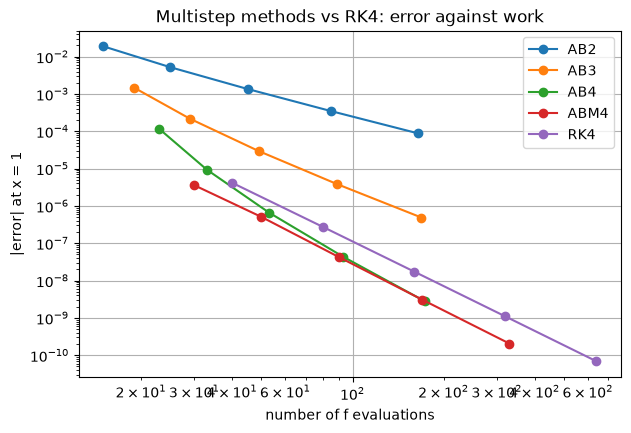

In [5]:
def evals(name, n):
    k = {"AB2": 2, "AB3": 3, "AB4": 4, "ABM4": 4}.get(name, 0)
    if name == "RK4":
        return 4 * n
    start = 4 * (k - 1) + k                           # RK4 starting steps + initial slopes
    return start + (n - (k - 1)) * (2 if name == "ABM4" else 1)

runs = {
    "AB2": lambda n: adams_bashforth(f, 0, 1, 1 / n, n, 2)[1][-1],
    "AB3": lambda n: adams_bashforth(f, 0, 1, 1 / n, n, 3)[1][-1],
    "AB4": lambda n: adams_bashforth(f, 0, 1, 1 / n, n, 4)[1][-1],
    "ABM4": lambda n: abm4(f, 0, 1, 1 / n, n)[1][-1],
    "RK4": lambda n: rk4(f, 0, 1, 1 / n, n)[1][-1],
}
ns = [10, 20, 40, 80, 160]
print(f"{'n':>5}" + "".join(f"{m:>11}{'ratio':>7}" for m in runs))
table = {m: [abs(exact(1) - run(n)) for n in ns] for m, run in runs.items()}
for i, n in enumerate(ns):
    print(f"{n:5d}" + "".join(f"{table[m][i]:11.2e}" + (f"{table[m][i-1] / table[m][i]:7.1f}" if i else " " * 7) for m in runs))

for m in runs:
    plt.loglog([evals(m, n) for n in ns], table[m], "o-", label=m)
plt.xlabel("number of f evaluations"); plt.ylabel("|error| at x = 1")
plt.title("Multistep methods vs RK4: error against work"); plt.legend();

The ratios approach $2^k$ for AB$k$ and $16$ for ABM4, confirming the orders. Against **work**, the fourth-order Adams methods beat RK4 on this problem because they need fewer evaluations per step; ABM4 is also more accurate than AB4 for the same step. This is why multistep methods are attractive when $f$ is expensive to evaluate.

The trade-offs:
* they need starting values, and changing the step size is awkward (the formulas assume equally spaced past points, so the history has to be interpolated or the coefficients recomputed);
* their stability regions are smaller (Section 7.7).

Variable-order, variable-step Adams codes (such as `LSODA`'s non-stiff mode or MATLAB's `ode113`) handle these issues and are very efficient for smooth problems with expensive $f$.

## 7.6 Zero-stability: a new way to fail

Multistep methods can fail in a way one-step methods cannot. Consider

$$y_{n+2} + 4y_{n+1} - 5y_n = h\,(4f_{n+1} + 2f_n).$$

It is consistent, and in fact has order 3: it integrates $y = 1, x, x^2, x^3$ exactly (Exercise 3). It even uses only one new evaluation per step. But look at the **characteristic polynomial** of its left-hand side,

$$\rho(\zeta) = \zeta^2 + 4\zeta - 5 = (\zeta - 1)(\zeta + 5).$$

For a tiny $h$ the method is essentially $y_{n+2} + 4y_{n+1} - 5y_n = 0$, whose solutions are combinations of $1^n$ and $(-5)^n$. The root $\zeta = 1$ is the one that follows the true solution. The **parasitic** root $\zeta = -5$ multiplies any small error, even rounding, by $-5$ at every step.

In [6]:
def bad_method(f, x0, y0, h, n):
    x = x0 + h * np.arange(n + 1)
    y = np.zeros(n + 1)
    y[0], y[1] = y0, exact(x0 + h)                  # even a perfect starting value
    for i in range(n - 1):
        y[i + 2] = -4 * y[i + 1] + 5 * y[i] + h * (4 * f(x[i + 1], y[i + 1]) + 2 * f(x[i], y[i]))
    return x, y

for h in [0.1, 0.05, 0.025, 0.0125]:
    x, y = bad_method(f, 0, 1, h, round(1 / h))
    print(f"h = {h:7.4f}:  error at x = 1 is {abs(exact(1) - y[-1]):.2e}")

h =  0.1000:  error at x = 1 is 5.69e+00
h =  0.0500:  error at x = 1 is 3.24e+06
h =  0.0250:  error at x = 1 is 1.87e+19
h =  0.0125:  error at x = 1 is 1.04e+46


The error **grows** as $h$ is made smaller: smaller steps mean more steps, and every step multiplies the parasitic error by $5$. The method is consistent but does **not converge**.

**Root condition.** A linear multistep method is **zero-stable** if all roots of $\rho(\zeta) = \sum_j \alpha_j\zeta^j$ satisfy $|\zeta| \le 1$, and any root with $|\zeta| = 1$ is simple. For Adams methods $\rho(\zeta) = \zeta^k - \zeta^{k-1} = \zeta^{k-1}(\zeta - 1)$, with roots $1$ and $0$: always zero-stable.

**Dahlquist's equivalence theorem.** A consistent linear multistep method converges **if and only if** it is zero-stable. This is the precise form of "consistency + stability = convergence" from the [chapter introduction](index.ipynb).

**Dahlquist's first barrier.** A zero-stable $k$-step method has order at most $k + 1$ if $k$ is odd and $k + 2$ if $k$ is even, and at most $k$ if it is explicit. The method above has order 3 with $k = 2$, more than an explicit 2-step method is allowed, and it pays for that with zero-instability.

## 7.7 Absolute stability regions

Applying a linear multistep method to $y' = \lambda y$ gives the recurrence $\sum_j(\alpha_j - z\beta_j)\,y_{n+j} = 0$, with $z = h\lambda$. It is stable when all roots of $\rho(\zeta) - z\,\sigma(\zeta)$, where $\sigma(\zeta) = \sum_j\beta_j\zeta^j$, lie in the unit disc. The boundary of the stability region is where a root has $|\zeta| = 1$, that is, $\zeta = e^{i\theta}$, which gives the **boundary locus**

$$z(\theta) = \frac{\rho(e^{i\theta})}{\sigma(e^{i\theta})}, \qquad 0 \le \theta \le 2\pi.$$

AB1: stable on the negative real axis for h|λ| ≤ 2.000
AB2: stable on the negative real axis for h|λ| ≤ 1.000
AB3: stable on the negative real axis for h|λ| ≤ 0.545
AB4: stable on the negative real axis for h|λ| ≤ 0.300
RK4: stable on the negative real axis for h|λ| ≤ 2.785


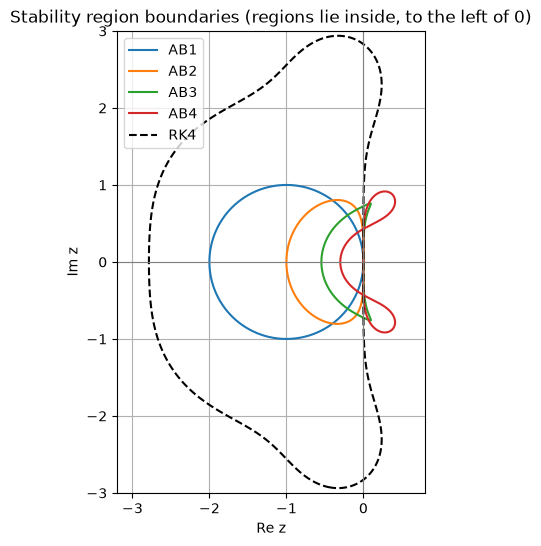

In [7]:
theta = np.linspace(0, 2 * np.pi, 2000)
zeta = np.exp(1j * theta)
fig, ax = plt.subplots(figsize=(7, 6))
for k in range(1, 5):
    rho = zeta**k - zeta**(k - 1)
    sigma = sum(AB[k][i] * zeta**(k - 1 - i) for i in range(k))
    zb = rho / sigma
    ax.plot(zb.real, zb.imag, label=f"AB{k}")

# RK4 boundary for comparison: |R(z)| = 1
re, im = np.meshgrid(np.linspace(-3.2, 0.8, 500), np.linspace(-3, 3, 500))
Z = re + 1j * im
R4 = 1 + Z + Z**2 / 2 + Z**3 / 6 + Z**4 / 24
ax.contour(re, im, np.abs(R4), levels=[1], colors="k", linestyles="--")
ax.plot([], [], "k--", label="RK4")
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set_xlim(-3.2, 0.8); ax.set_ylim(-3, 3); ax.set_aspect("equal")
ax.set_xlabel("Re z"); ax.set_ylabel("Im z")
ax.set_title("Stability region boundaries (regions lie inside, to the left of 0)")
ax.legend();

for k, lim in [(1, 2), (2, 1), (3, 6 / 11), (4, 3 / 10)]:
    print(f"AB{k}: stable on the negative real axis for h|λ| ≤ {lim:.3f}")
print("RK4: stable on the negative real axis for h|λ| ≤ 2.785")

The Adams–Bashforth regions **shrink** as the order increases, and AB4's is tiny compared with RK4's. Even after dividing by RK4's four evaluations per step ($2.785/4 \approx 0.70$ per evaluation, against $0.3$ for AB4), RK4 gets more stability for the same work. Explicit multistep methods are therefore a poor choice for stiff problems. The multistep methods used for stiff problems are the implicit **backward differentiation formulas (BDF)**, which have very large stability regions; they are what `ode15s` and `solve_ivp(method="BDF")` use.

## 7.8 Summary

* Multistep methods reuse past slopes: one (AB) or two (ABM, PECE) evaluations of $f$ per step at any order.
* Adams–Bashforth (explicit, order $k$) and Adams–Moulton (implicit, order $k + 1$) come from integrating an interpolating polynomial.
* They need starting values from a one-step method of the same order, and changing $h$ is awkward.
* A consistent multistep method converges if and only if it is **zero-stable** (root condition).
* Explicit Adams methods have small stability regions; stiff problems call for implicit BDF methods.

## Exercises

1. Derive the AB3 coefficients by hand from $\sum_j\beta_jt_j^m = \frac{1}{m+1}$ with nodes $t = 0, -1, -2$.
2. Show that the one-step Adams–Moulton method is the trapezoidal rule.
3. Check that $y_{n+2} + 4y_{n+1} - 5y_n = h(4f_{n+1} + 2f_n)$ is exact for $y = 1, x, x^2, x^3$ but not for $x^4$. (Take $x_n = 0$, $h = 1$.)
4. Why is it hard to change the step size in the middle of an Adams–Bashforth computation?

**Answers**

1. $\beta_0 + \beta_1 + \beta_2 = 1$, $\ -\beta_1 - 2\beta_2 = \tfrac12$, $\ \beta_1 + 4\beta_2 = \tfrac13$. Adding the last two: $2\beta_2 = \tfrac56$, so $\beta_2 = \tfrac{5}{12}$, $\beta_1 = -\tfrac{16}{12}$, $\beta_0 = \tfrac{23}{12}$.
2. With nodes $t = 1, 0$: $\beta_0 + \beta_1 = 1$ and $\beta_0 = \tfrac12$, so $y_{n+1} = y_n + \tfrac{h}{2}(f_{n+1} + f_n)$.
3. See the cell below: the residual is $0$ for degrees $0$–$3$ and $4$ for $x^4$.
4. The coefficients were derived for equally spaced past points $x_n, x_n - h, x_n - 2h, \dots$. After a change of step size the stored slopes are no longer at those points, so either new coefficients must be computed for the uneven spacing or the past values must be interpolated onto the new grid.

In [8]:
print("1.  AB3 coefficients ×12:", np.round(AB[3] * 12, 10))
print("2.  AM1 coefficients:", AM[1])
for m in range(5):
    y = lambda x: x**m
    dy = lambda x: m * x**(m - 1) if m else 0
    lhs = y(2) + 4 * y(1) - 5 * y(0)
    rhs = 4 * dy(1) + 2 * dy(0)
    print(f"3.  y = x^{m}:  LHS − RHS = {lhs - rhs}")

1.  AB3 coefficients ×12: [ 23. -16.   5.]
2.  AM1 coefficients: [0.5 0.5]
3.  y = x^0:  LHS − RHS = 0
3.  y = x^1:  LHS − RHS = 0
3.  y = x^2:  LHS − RHS = 0
3.  y = x^3:  LHS − RHS = 0
3.  y = x^4:  LHS − RHS = 4
